# Experiment 2: The eight queens problem
Generate-and-test over permutations versus backtracking with pruning, n = 4 to 10.

In [1]:
import json, platform, subprocess, time
from itertools import permutations
import matplotlib.pyplot as plt

def cpu_name():
    try:
        out = subprocess.run(["powershell", "-NoProfile", "-Command",
                              "(Get-CimInstance Win32_Processor).Name"], capture_output=True, text=True)
        return out.stdout.strip() or platform.processor()
    except OSError:
        return platform.processor()

R = {"python": platform.python_version(), "cpu": cpu_name(), "os": platform.platform()}
print(R)

{'python': '3.13.5', 'cpu': '11th Gen Intel(R) Core(TM) i7-1165G7 @ 2.80GHz', 'os': 'Windows-11-10.0.26300-SP0'}


## Generate and test
`board[c]` is the row of the queen in column c. Permutations already rule out shared rows and columns,
so only the diagonal test |r_i - r_j| = |i - j| is left.

In [2]:
def conflicts(board):
    """Number of attacking pairs."""
    n, bad = len(board), 0
    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == j - i:
                bad += 1
    return bad

def generate_and_test(n):
    return [p for p in permutations(range(n)) if conflicts(p) == 0]

## Backtracking with pruning

In [3]:
def is_safe(board, col, row):
    """Only columns 0..col-1 hold queens, so only they are checked."""
    for c in range(col):
        if board[c] == row or abs(board[c] - row) == col - c:
            return False
    return True

def backtrack(n):
    sols, nodes = [], 0
    board = [-1] * n
    def place(col):
        nonlocal nodes
        if col == n:
            sols.append(tuple(board)); return
        for row in range(n):
            nodes += 1
            if is_safe(board, col, row):
                board[col] = row          # place
                place(col + 1)
                board[col] = -1           # undo
    place(0)
    return sols, nodes

sols8, nodes8 = backtrack(8)
assert len(sols8) == 92 and set(sols8) == set(generate_and_test(8))   # both methods agree exactly
print(len(sols8), "solutions,", nodes8, "nodes; first:", sols8[0])

92 solutions, 15720 nodes; first: (0, 4, 7, 5, 2, 6, 1, 3)


## Scaling n = 4 to 10 (best of 3 timings for backtracking, 1 for generate-and-test at n = 10)

In [4]:
def timed(fn, n, repeats):
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter(); out = fn(n); best = min(best, time.perf_counter() - t0)
    return out, best

rows = []
for n in range(4, 11):
    (s, nd), tb = timed(backtrack, n, 3)
    g, tg = timed(generate_and_test, n, 1 if n >= 10 else 3)
    assert len(s) == len(g)
    rows.append(dict(n=n, solutions=len(s), nodes=nd, t_backtrack=tb, t_generate=tg))
    print(f"{n:>3} {len(s):>5} {nd:>8} {tb:9.4f}s {tg:9.4f}s")
R["table"] = rows

  4     2       60    0.0001s    0.0001s
  5    10      220    0.0002s    0.0011s
  6     4      894    0.0011s    0.0049s


  7    40     3584    0.0049s    0.0471s


  8    92    15720    0.0192s    0.3917s


  9   352    72378    0.1195s    6.8529s


 10   724   348150    0.8673s   95.3321s


## Symmetry check: 92 solutions -> 12 fundamental

In [5]:
def symmetries(b):
    n = len(b); pts = [(r, c) for c, r in enumerate(b)]
    out = set()
    for _ in range(4):
        pts = [(c, n - 1 - r) for r, c in pts]                 # rotate 90 degrees
        for q in (pts, [(r, n - 1 - c) for r, c in pts]):      # and its mirror image
            board = [0] * n
            for r, c in q: board[c] = r
            out.add(tuple(board))
    return out

classes = {min(symmetries(s)) for s in sols8}
images = sorted(len(symmetries(s)) for s in classes)
R["fundamental"] = len(classes); R["images_per_class"] = images
print(len(classes), "fundamental solutions; images per class:", images)

12 fundamental solutions; images per class: [4, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8]


## Figures

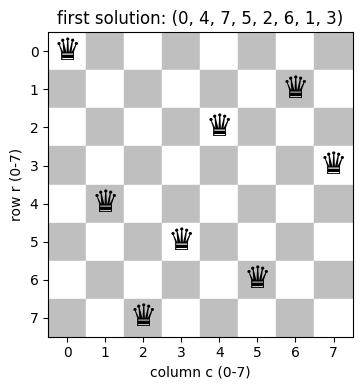

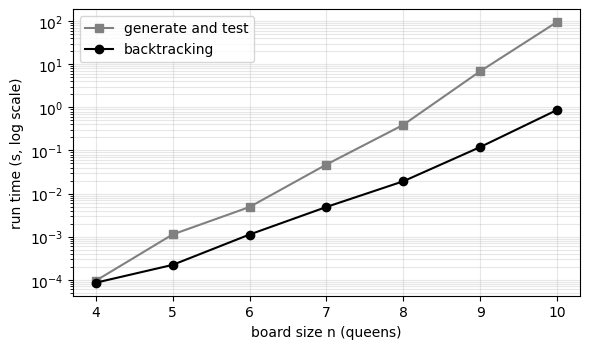

In [6]:
first = sols8[0]
fig, ax = plt.subplots(figsize=(4, 4))
for r in range(8):
    for c in range(8):
        ax.add_patch(plt.Rectangle((c, r), 1, 1, color="0.75" if (r + c) % 2 else "w"))
for c, r in enumerate(first):
    ax.text(c + 0.5, r + 0.5, "♛", ha="center", va="center", fontsize=22)
ax.set(xlim=(0, 8), ylim=(8, 0), aspect="equal", xlabel="column c (0-7)", ylabel="row r (0-7)",
       xticks=[i + 0.5 for i in range(8)], yticks=[i + 0.5 for i in range(8)],
       xticklabels=range(8), yticklabels=range(8), title=f"first solution: {first}")
fig.tight_layout(); fig.savefig("figs/fig2_1_board.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.6))
ns = [r["n"] for r in rows]
ax.semilogy(ns, [r["t_generate"] for r in rows], "s-", color="0.5", label="generate and test")
ax.semilogy(ns, [r["t_backtrack"] for r in rows], "o-", color="k", label="backtracking")
ax.set(xlabel="board size n (queens)", ylabel="run time (s, log scale)")
ax.grid(alpha=0.3, which="both"); ax.legend()
fig.tight_layout(); fig.savefig("figs/fig2_2_runtime.png", dpi=150); plt.show()

In [7]:
json.dump(R, open("results.json", "w"), indent=1)